# Autism Screening Prediction

**Exploratory analysis, preprocessing, and model comparison**

This notebook examines an 800-record screening dataset, summarizes its distributions and data-quality considerations, then trains and evaluates classification models. The target is a screening label; model predictions should not be interpreted as a clinical diagnosis.

---

## 1. Libraries and setup

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split , cross_val_score , RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix , classification_report , accuracy_score
from xgboost import XGBClassifier
import pickle

## 2. Load and understand the data

The source file is loaded into a pandas DataFrame. The inspection below checks its dimensions, columns, types, sample records, and category values before preparing the analysis table.

In [4]:
#READ THE CSV DATA TO A PANDAS DATAFRAME
df = pd.read_csv("/content/train (2).csv")

### Initial inspection

Review the first and last records, column types, and value domains. The saved inspection reports **800 rows and 22 columns**. The dataset has no blank/NaN values in the recorded `info()` output; however, some fields use `?` as a text placeholder, which requires separate handling.

In [5]:
df.shape

(800, 22)

In [6]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,...,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,...,m,?,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,...,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,...,f,?,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,...,m,?,no,no,South Africa,no,-4.777286,18 and more,Self,0


In [7]:
df.tail()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,...,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
795,796,0,1,0,0,0,0,0,0,1,...,m,Hispanic,no,no,New Zealand,no,12.999501,18 and more,Self,0
796,797,0,1,1,0,0,1,0,1,1,...,m,White-European,no,no,Cyprus,no,13.561518,18 and more,Self,0
797,798,0,0,0,0,0,0,0,0,0,...,m,South Asian,yes,no,New Zealand,no,2.653177,18 and more,Self,0
798,799,0,0,0,0,0,0,0,0,0,...,f,?,no,no,Canada,no,9.069342,18 and more,Self,0
799,800,0,1,0,0,0,0,0,0,0,...,f,?,no,no,United Arab Emirates,yes,2.243304,18 and more,Self,0


In [8]:
#display all columns of a dataframe
pd.set_option('display.max_columns', None)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

In [10]:
#convert age column to integer
df["age"] = df["age"].astype(int)

In [11]:
df.head(2)

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,18 and more,Self,0


In [12]:
for col in df.columns:
  numerical_features = ["ID" , "age" , "result"]
  if col not in numerical_features:
                        print(col,df[col].unique())
                        print("-"*50)

A1_Score [1 0]
--------------------------------------------------
A2_Score [0 1]
--------------------------------------------------
A3_Score [1 0]
--------------------------------------------------
A4_Score [0 1]
--------------------------------------------------
A5_Score [1 0]
--------------------------------------------------
A6_Score [0 1]
--------------------------------------------------
A7_Score [1 0]
--------------------------------------------------
A8_Score [0 1]
--------------------------------------------------
A9_Score [1 0]
--------------------------------------------------
A10_Score [1 0]
--------------------------------------------------
gender ['f' 'm']
--------------------------------------------------
ethnicity ['?' 'White-European' 'Middle Eastern ' 'Pasifika' 'Black' 'Others'
 'Hispanic' 'Asian' 'Turkish' 'South Asian' 'Latino' 'others']
--------------------------------------------------
jaundice ['no' 'yes']
--------------------------------------------------
austim

In [13]:
# dropping ID and age_desc column
df = df.drop(columns = ["ID" , "age_desc"])


In [14]:
df.shape

(800, 20)

In [15]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [16]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [17]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Viet Nam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'AmericanSamoa', 'Bahamas', 'Saudi Arabia',
       'Ireland', 'Aruba', 'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan',
       'Armenia', 'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'Hong Kong',
       'Angola', 'China', 'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran',
       'Argentina', 'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone',
       'Czech Republic', 'Niger', 'Romania', 'Cyprus', 'Belgium',
       'Burundi', 'Bangladesh'], dtype=object)

In [18]:
# define the mapping dictionary for country names

mapping = {
    "Viet Nam" : "Vietnam",
    "AmericanSamoa" : "United States",
    "Hong Kong" : "China"
}

#  replace the value in the counrty column

df["contry_of_res"] = df["contry_of_res"].replace(mapping)


In [19]:
df['contry_of_res'].unique()

array(['Austria', 'India', 'United States', 'South Africa', 'Jordan',
       'United Kingdom', 'Brazil', 'New Zealand', 'Canada', 'Kazakhstan',
       'United Arab Emirates', 'Australia', 'Ukraine', 'Iraq', 'France',
       'Malaysia', 'Vietnam', 'Egypt', 'Netherlands', 'Afghanistan',
       'Oman', 'Italy', 'Bahamas', 'Saudi Arabia', 'Ireland', 'Aruba',
       'Sri Lanka', 'Russia', 'Bolivia', 'Azerbaijan', 'Armenia',
       'Serbia', 'Ethiopia', 'Sweden', 'Iceland', 'China', 'Angola',
       'Germany', 'Spain', 'Tonga', 'Pakistan', 'Iran', 'Argentina',
       'Japan', 'Mexico', 'Nicaragua', 'Sierra Leone', 'Czech Republic',
       'Niger', 'Romania', 'Cyprus', 'Belgium', 'Burundi', 'Bangladesh'],
      dtype=object)

In [20]:
# target class distribution

df["Class/ASD"].value_counts()

,count
Class/ASD,
0,639
1,161


### Data preparation notes

- The raw table contains **800 records and 22 columns**. The `info()` output shows 800 non-null values in each field, but `?` appears as a category in `ethnicity` and `relation`; these are placeholder values rather than true nulls.
- `age_desc` contains only `18 and more` in the saved inspection, so it adds no variation and is removed. `ID` is also removed because it is an identifier, not a respondent attribute.
- Three country labels are standardized (`Viet Nam`, `AmericanSamoa`, and `Hong Kong`) to improve naming consistency. This is label cleanup, not geographic regrouping.
- The target contains **639 class-0 records (79.9%) and 161 class-1 records (20.1%)**, about a **4:1** imbalance. Accuracy alone may therefore hide weaker detection of class 1; later evaluation should be read alongside class-specific recall and F1.

## 3. Exploratory data analysis (EDA)

EDA describes the sample and flags patterns that affect preprocessing and evaluation. It is descriptive: associations in this dataset do not establish causes or clinical validity.

In [21]:
df.shape

(800, 20)

In [22]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

In [23]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,f,?,no,no,Austria,no,6.351166,Self,0
1,0,0,0,0,0,0,0,0,0,0,47,m,?,no,no,India,no,2.255185,Self,0
2,1,1,1,1,1,1,1,1,1,1,7,m,White-European,no,yes,United States,no,14.851484,Self,1
3,0,0,0,0,0,0,0,0,0,0,23,f,?,no,no,United States,no,2.276617,Self,0
4,0,0,0,0,0,0,0,0,0,0,43,m,?,no,no,South Africa,no,-4.777286,Self,0


In [24]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result,Class/ASD
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.560000,0.530000,0.450000,0.41500,0.395000,0.303750,0.397500,0.508750,0.495000,0.617500,27.963750,8.537303,0.201250
std,0.496697,0.499411,0.497805,0.49303,0.489157,0.460164,0.489687,0.500236,0.500288,0.486302,16.329827,4.807676,0.401185
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,-6.137748,0.000000
25%,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,5.306575,0.000000
50%,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,24.000000,9.605299,0.000000
75%,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.250000,12.514484,0.000000
max,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,89.000000,15.853126,1.000000


### Univariate analysis

Start with one-variable distributions to understand scale, spread, and category concentration before comparing features with the target.

#### Numeric features

**Age** is measured in years. **`result`** is the supplied numeric screening score. The ten `A*_Score` fields are binary responses and are treated as categorical in the next section.

In [25]:
# set the desired theme
sns.set_theme(style="whitegrid")

##### Distribution plots

The vertical reference lines mark each variable?s mean and median. Differences between them help indicate asymmetry; the KDE curve is a smoothed visual guide, not an additional measurement.

Mean of Age: 27.96375
Median of Age: 24.0


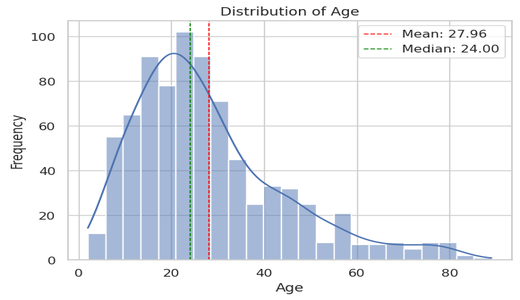

In [29]:
# Histogram for "age"

plt.figure(figsize=(5.2, 3.0))
sns.histplot(df["age"], kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

#calulate mean and median
age_mean = df["age"].mean()
age_median = df["age"].median()

print("Mean of Age:", age_mean)
print("Median of Age:", age_median)

#add vertiCAL lines for mean and median
plt.axvline(age_mean, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {age_mean:.2f}')
plt.axvline(age_median, color='green', linestyle='dashed', linewidth=1, label=f'Median: {age_median:.2f}')
plt.legend()

plt.show()

Mean of result: 8.537303106501248
Median of result: 9.605299308


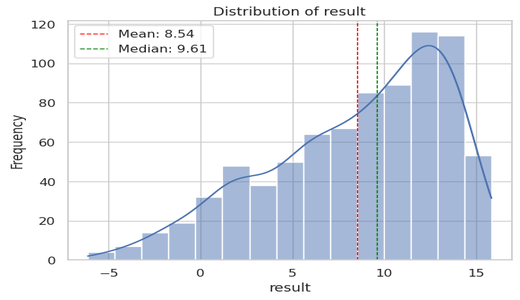

In [30]:
# Histogram for "result"

plt.figure(figsize=(5.2, 3.0))
sns.histplot(df["result"], kde=True)
plt.title("Distribution of result")
plt.xlabel("result")
plt.ylabel("Frequency")

#calulate mean and median
result_mean = df["result"].mean()
result_median = df["result"].median()

print("Mean of result:", result_mean)
print("Median of result:", result_median)

#add vertical lines for mean and median
plt.axvline(result_mean, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {result_mean:.2f}')
plt.axvline(result_median, color='green', linestyle='dashed', linewidth=1, label=f'Median: {result_median:.2f}')
plt.legend()

plt.show()

##### Box plots and IQR flags

The box plots summarize the middle 50% of each numeric feature. The following cells use the 1.5?IQR rule to count observations outside the whisker bounds. These flags identify unusual values for review; they do not by themselves prove that a record is erroneous.

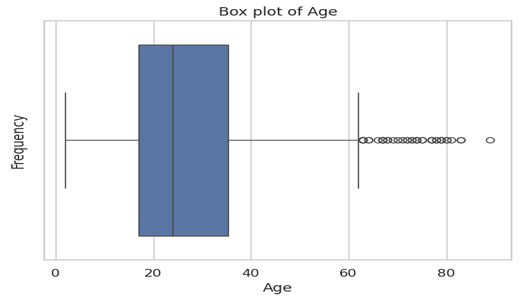

In [31]:
# box plots

plt.figure(figsize=(5.2, 3.0))
sns.boxplot(x=df["age"])
plt.title("Box plot of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


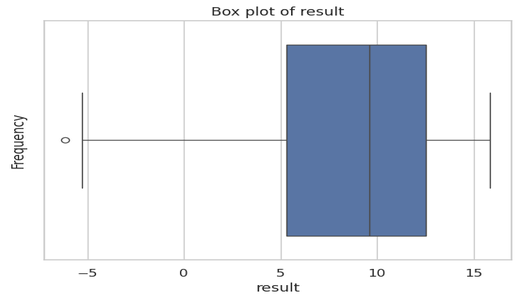

In [32]:
# box plots

plt.figure(figsize=(5.2, 3.0))
sns.boxplot(x=df["result"])
plt.title("Box plot of result")
plt.xlabel("result")
plt.ylabel("Frequency")
plt.show()

In [33]:

# count the outliers using IQR method

Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df[(df["age"] < lower_bound) | (df["age"] > upper_bound)]


In [34]:
len(age_outliers)

39

In [35]:

# count the outliers using IQR method

Q1 = df["result"].quantile(0.25)
Q3 = df["result"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

result_outliers = df[(df["result"] < lower_bound) | (df["result"] > upper_bound)]


In [36]:
len(result_outliers)

1

#### Categorical features

The count plots show category frequencies for the ten binary screening responses and demographic/context fields. Frequencies reflect this dataset?s sample composition; they should not be read as population prevalence.

In [37]:
df.columns

Index(['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
       'result', 'relation', 'Class/ASD'],
      dtype='object')

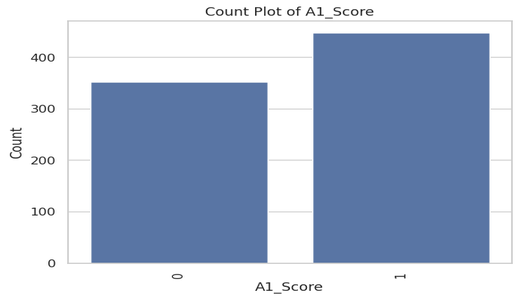

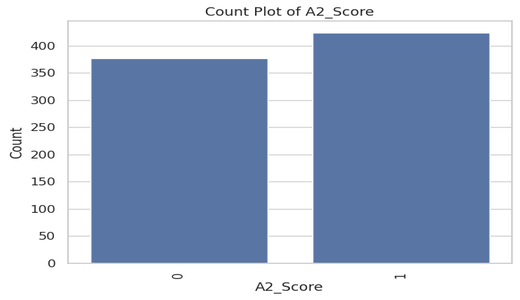

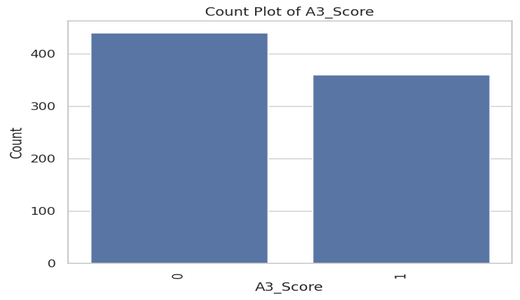

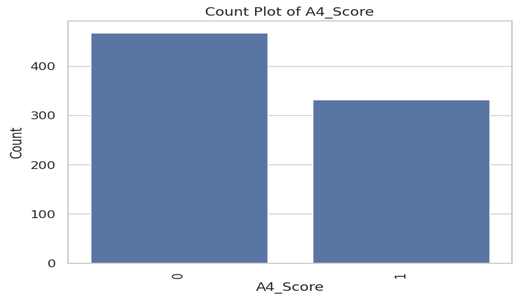

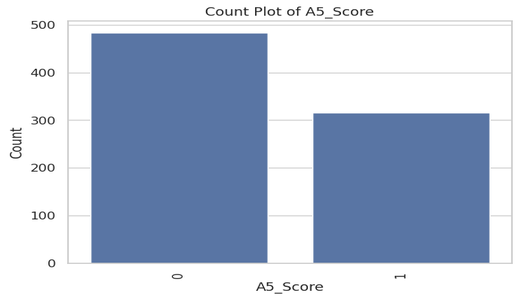

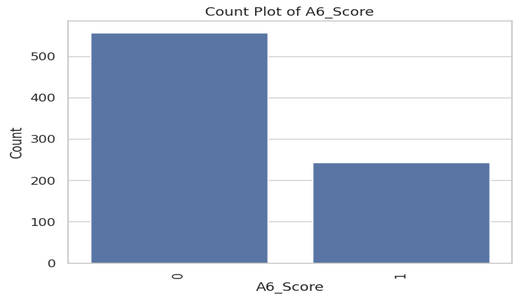

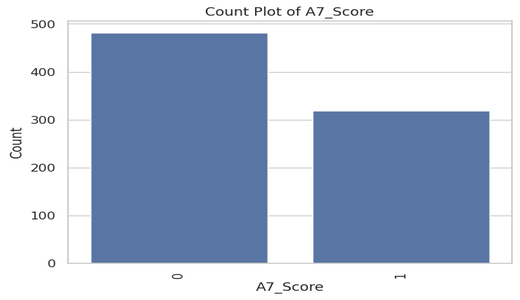

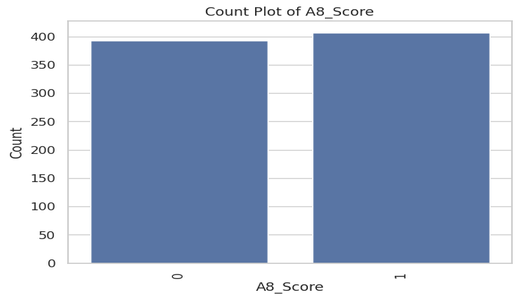

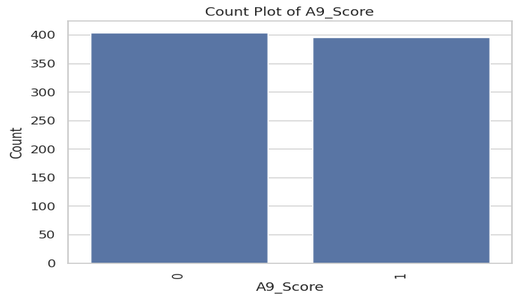

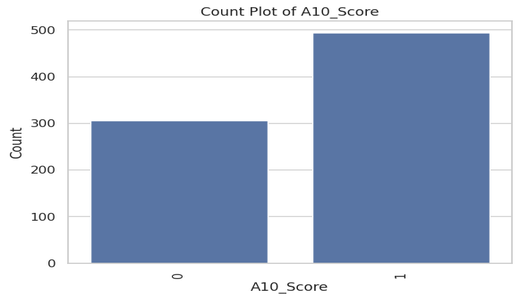

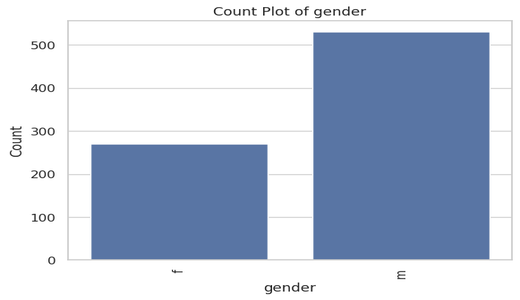

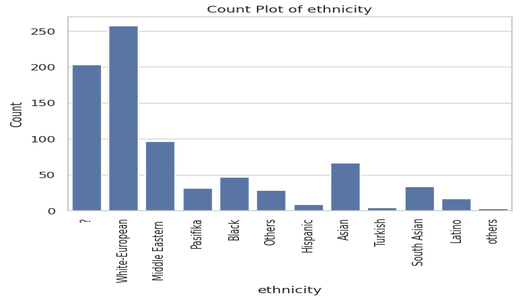

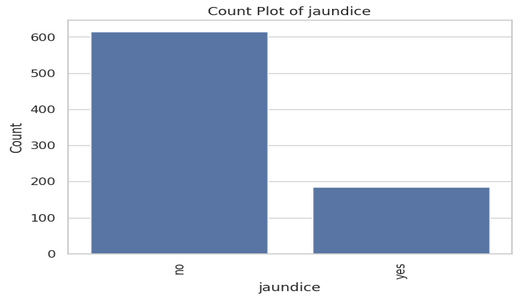

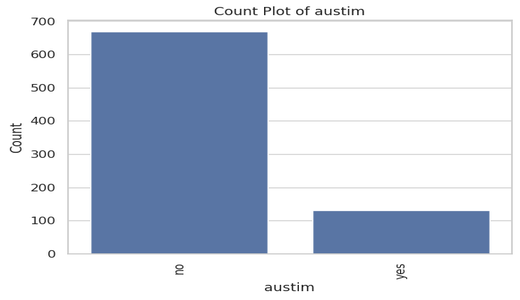

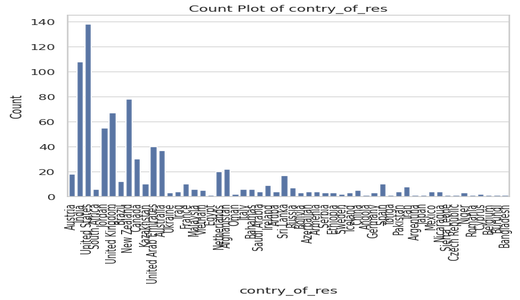

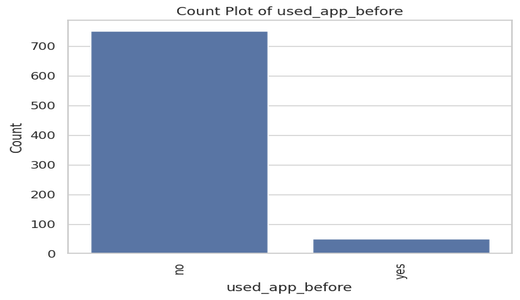

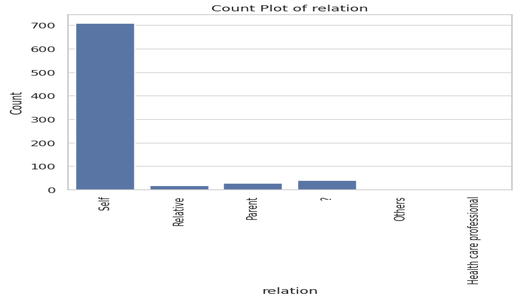

In [38]:
categorical_columns=['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score',
       'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score',  'gender',
       'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'used_app_before',
        'relation', ]

for col in categorical_columns:
  plt.figure(figsize=(5.2, 3.0))
  sns.countplot(x=df[col])
  plt.title(f"Count Plot of {col}")
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.xticks(rotation=90)
  plt.show()

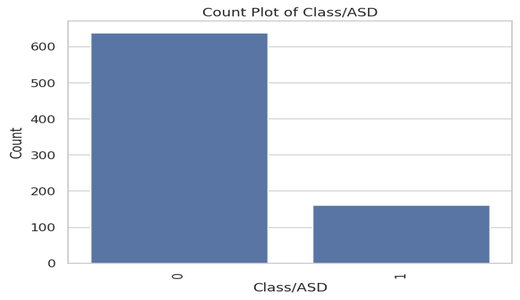

In [39]:
# countplot for the target column (Class/ASD)

plt.figure(figsize=(5.2, 3.0))
sns.countplot(x=df["Class/ASD"])
plt.title("Count Plot of Class/ASD")
plt.xlabel("Class/ASD")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

##### Standardize placeholder categories for encoding

`?` is used as a text placeholder in `ethnicity` and `relation`. The recoding below groups these values with an `Others` label so the later encoder can handle them consistently. Combining relation categories is a modeling choice and reduces detail in the original categories.

In [40]:
df["ethnicity"] = df["ethnicity"].replace({"?":"Others" , "others":"Others"})

In [41]:
df["relation"].unique()

array(['Self', 'Relative', 'Parent', '?', 'Others',
       'Health care professional'], dtype=object)

In [42]:
df["relation"] = df["relation"].replace({"?":"Others" , "Relative":"Others" , "Parent":"Others" , "Health care professional":"Others"})

### Encode categorical fields

Label encoding converts the remaining text fields to integer codes so the downstream estimators can consume them. For nominal variables, these integers are category identifiers; their numeric ordering should not be interpreted as meaningful distance.

In [43]:
# identify columns with "object" datatype
object_columns = df.select_dtypes(include=["object"]).columns

In [44]:
print(object_columns)

Index(['gender', 'ethnicity', 'jaundice', 'austim', 'contry_of_res',
       'used_app_before', 'relation'],
      dtype='object')


In [45]:
# initialize a dictionary to store the encoders
encoders = {}

#apply label encoding and store the encoders
for column in object_columns :
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoders[column]= label_encoder  #saving the encoder for this column

# save the encoders as a pickle file
with open("encoders.pkl", "wb") as file:
  pickle.dump(encoders, file)

In [46]:
encoders

{'gender': LabelEncoder(),
 'ethnicity': LabelEncoder(),
 'jaundice': LabelEncoder(),
 'austim': LabelEncoder(),
 'contry_of_res': LabelEncoder(),
 'used_app_before': LabelEncoder(),
 'relation': LabelEncoder()}

In [47]:
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,relation,Class/ASD
0,1,0,1,0,1,0,1,0,1,1,38,0,5,0,0,6,0,6.351166,1,0
1,0,0,0,0,0,0,0,0,0,0,47,1,5,0,0,23,0,2.255185,1,0
2,1,1,1,1,1,1,1,1,1,1,7,1,9,0,1,52,0,14.851484,1,1
3,0,0,0,0,0,0,0,0,0,0,23,0,5,0,0,52,0,2.276617,1,0
4,0,0,0,0,0,0,0,0,0,0,43,1,5,0,0,44,0,-4.777286,1,0


### Bivariate analysis

The correlation heatmap summarizes pairwise Pearson correlations after categorical label encoding. It is useful as a quick scan, but correlations involving encoded nominal categories can depend on arbitrary code assignments and should not be treated as strong evidence of association.

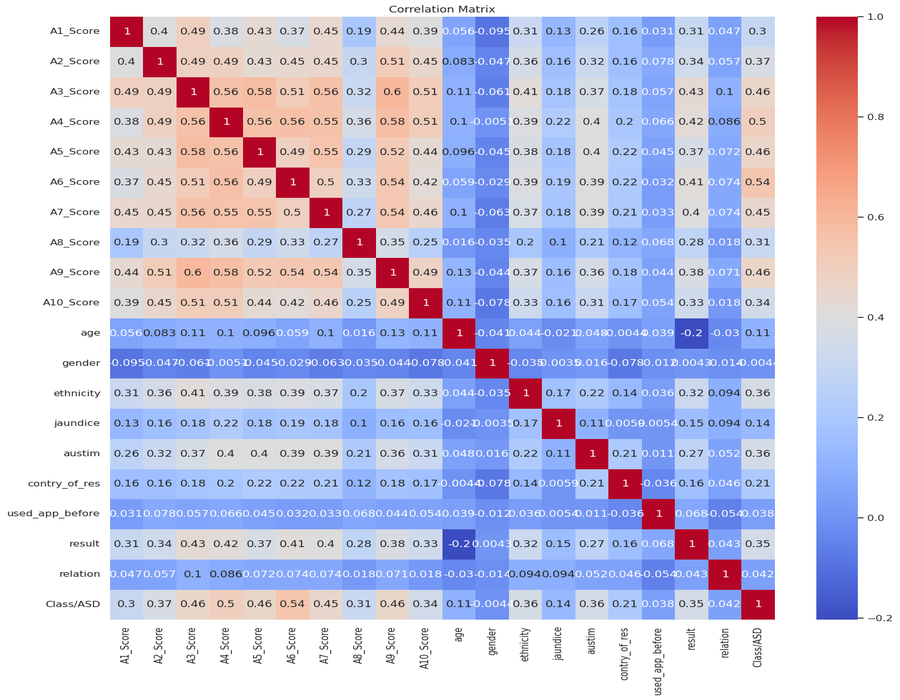

In [50]:
# correlation matrix
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, annot_kws={"size": 7}, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### EDA findings and implications

- **Sample and target:** The saved outputs show 800 records; 161 (20.1%) are class 1 and 639 (79.9%) are class 0. The roughly 4:1 imbalance motivates reporting class-specific recall, precision, and F1 in addition to overall accuracy. The model?s later test report is consistent with this concern: class-1 recall is 0.69 and class-1 F1 is 0.66, below class 0 (0.88 recall, 0.89 F1).
- **Age distribution:** Mean age is **27.96 years**, compared with a median of **24 years**. The mean being above the median suggests a longer upper-age tail in this sample. The interquartile range is **17 to 35.25 years**; the observed range is **2 to 89 years**, so the sample spans a broad age range.
- **Screening score:** `result` has mean **8.54**, median **9.61**, standard deviation **4.81**, and range **?6.14 to 15.85**. The mean below the median suggests some lower values pull the average down. Confirm the score?s intended scale and whether negative values are valid before interpreting its magnitude.
- **IQR outlier flags:** The saved calculations flag **39 age values** and **1 `result` value**. These are statistical flags, not automatic errors. Replacing every flagged value with a median may compress genuine variation, so the preprocessing choice should be interpreted as a modeling assumption.
- **Placeholder and encoding considerations:** `info()` reports no NaN cells, while `?` occurs in `ethnicity` and `relation`. This distinction matters: missingness is represented as a string and must be handled explicitly. Grouping relation categories and label-encoding nominal categories makes the model input usable but loses some category detail and can impose artificial ordering for some estimators.
- **Correlation caveat:** The heatmap does not show a clearly dominant linear relationship, but this does not establish feature independence. In particular, integer codes for nominal categories can make Pearson correlations misleading; the heatmap is a screening view rather than a feature-selection test.
- **Representativeness:** The recorded data covers many country labels and a wide age range, but no sampling design or population weighting is shown. The category counts therefore describe this dataset only and may not generalize to other settings.

These observations support the later minority-class evaluation and careful interpretation of minority-class performance. They do not establish diagnostic accuracy or clinical suitability.

## 4. Data preprocessing

### Handle numeric outliers

A median replacement rule is applied to values outside the 1.5?IQR bounds. This limits the influence of extreme values on selected models, while assuming those extremes should be capped to a typical value.

In [51]:
#function to replace the outliers with median

def replace_outliers_with_median(df,column):

  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  median = df[column].median()

  # replace outliers with median value

  df[column] = df[column].apply(lambda x : median if (x < lower_bound) or (x > upper_bound) else x)

  return df

In [52]:

# replace the outliers in the age column

df = replace_outliers_with_median(df,"age")

#replace the outliers in the result column

df = replace_outliers_with_median(df,"result")


### Split into training and test sets

The data is divided into an 80% training set and a 20% holdout test set. The test set remains separate from the oversampling step and is used for the final evaluation.

In [53]:
X = df.drop(columns = ["Class/ASD"])
y = df["Class/ASD"]

In [54]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

### Balance the training data with SMOTE

SMOTE is fitted only to the training split to synthesize minority-class examples. The held-out test set retains its original class distribution, so reported test performance reflects the observed imbalance.

In [55]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


In [57]:
print(y_train_resampled.shape)

(1030,)


In [59]:
print(y_train_resampled.value_counts())

Class/ASD
1    515
0    515
Name: count, dtype: int64


## 5. Model training and comparison

In [60]:
# LIST OF CLASSIFIERS

model = {
    "DecisionTreeClassifier" : DecisionTreeClassifier(random_state=42),
    "RandomForestClassifier" : RandomForestClassifier(random_state=42),
    "XGBClassifier" : XGBClassifier(random_state=42)
}





In [61]:
# dictionary to store the cross validation results

cv_scores = {}

# perform 5-fold cross validation for each model

for model_name , model in model.items():
  print(f"Training {model_name} with default parameters... ")
  scores = cross_val_score(model,X_train_resampled,y_train_resampled,cv=5,scoring="accuracy")
  cv_scores[model_name] = scores
  print(f"{model_name} Cross-Validation accuracy : {np.mean(scores):.2f}")
  print("-"*50)

Training DecisionTreeClassifier with default parameters... 
DecisionTreeClassifier Cross-Validation accuracy : 0.86
--------------------------------------------------
Training RandomForestClassifier with default parameters... 
RandomForestClassifier Cross-Validation accuracy : 0.92
--------------------------------------------------
Training XGBClassifier with default parameters... 
XGBClassifier Cross-Validation accuracy : 0.90
--------------------------------------------------


In [62]:
cv_scores

{'DecisionTreeClassifier': array([0.7961165 , 0.87864078, 0.87378641, 0.8592233 , 0.87378641]),
 'RandomForestClassifier': array([0.90776699, 0.92718447, 0.9223301 , 0.91747573, 0.9223301 ]),
 'XGBClassifier': array([0.86893204, 0.9223301 , 0.90776699, 0.90776699, 0.91262136])}

### Model selection and hyperparameter tuning

The parameter search compares tuned tree-based estimators using cross-validation on the resampled training data. Cross-validation scores are model-selection results; the untouched test set remains the final performance check.

In [64]:
#initializing modela

decision_tree_model = DecisionTreeClassifier(random_state=42)
random_forest_model = RandomForestClassifier(random_state=42)
xgb_model = XGBClassifier(random_state=42)


In [65]:
#Hyperparameter grids for  RandomizedSearchCV

param_grid_dt = {
    "criterion" : ["gini" , "entropy"],
    "max_depth" : [None , 10 , 20 , 30 , 50 , 70 ],
    "min_samples_split" : [2 , 5 , 10],
    "min_samples_leaf" : [1 , 2 , 4]
}

param_grid_rf = {
    "n_estimators" : [50,100,200,500],
    "max_depth" : [None , 10 , 20 , 30],
    "min_samples_split" : [2 , 5 , 10],
    "min_samples_leaf" : [1 , 2 , 4],
    "bootstrap" : [True , False]
}

param_grid_xgb = {
    "learning_rate" : [0.01 , 0.1 , 0.2 , 0.3],
    "n_estimators" : [50 , 100 , 200 , 500 ] ,
    "max_depth" : [3 , 5 , 7 , 10],
    "subsample" : [0.5 , 0.7 , 1.0],
    "colsample_bytree" : [0.5 , 0.7 , 1.0]

}



In [66]:
# hyperparameter tuning for 3 tree based models

# the below steps can be autometed by using a for loop or by using a pipeline

#perform RandomizedSeacrhCV for each model

random_search_dt = RandomizedSearchCV(estimator=decision_tree_model,param_distributions=param_grid_dt,n_iter=10,cv=5,scoring="accuracy",random_state=42)


random_search_rf = RandomizedSearchCV(estimator=random_forest_model,param_distributions=param_grid_rf,n_iter=10,cv=5,scoring="accuracy",random_state=42)


random_search_xgb = RandomizedSearchCV(estimator=xgb_model,param_distributions=param_grid_xgb, n_iter=10,cv=5,scoring="accuracy",random_state=42)





In [67]:
random_search_dt.fit(X_train_resampled,y_train_resampled)
random_search_rf.fit(X_train_resampled,y_train_resampled)
random_search_xgb.fit(X_train_resampled,y_train_resampled)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraint...
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   param_distributions={'colsample_bytree': [0.5, 0.7, 1.0],
                                        'learning_rate': [0.01, 0.1, 0.2, 0.3],
                                        'max_depth': [3, 5, 7, 10],
                                        'n_estimators': [50, 100, 200, 500],
                                        'subsample': [0.5, 0.7, 1.0]},
                   random_state=42, scoring='accuracy')

In [68]:
#get the model with the best score

best_model = None
best_score = 0

if random_search_dt.best_score_ > best_score:
  best_score = random_search_dt.best_score_
  best_model = random_search_dt.best_estimator_

if random_search_rf.best_score_ > best_score:
  best_score = random_search_rf.best_score_
  best_model = random_search_rf.best_estimator_

if random_search_xgb.best_score_ > best_score:
  best_score = random_search_xgb.best_score_
  best_model = random_search_xgb.best_estimator_



In [71]:
print(f"Best Model: {best_model}")
print(f"Best Score: {best_score}")


Best Model: RandomForestClassifier(bootstrap=False, max_depth=10, random_state=42)
Best Score: 0.9223300970873787


In [72]:
#save the best model

with open("best_model.pkl","wb") as file:
  pickle.dump(best_model,file)

## 6. Holdout evaluation

The final report evaluates the selected model on the 20% test split. Interpret class-specific metrics alongside accuracy because class 1 is the minority target.

In [74]:
# evaluate on the  test data
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test,y_test_pred)
print(f"Test Accuracy : {test_accuracy}")
print("Confusion Matrix :")
print(confusion_matrix(y_test,y_test_pred))
print("Classification Report :")
print(classification_report(y_test,y_test_pred))


Test Accuracy : 0.8375
Confusion Matrix :
[[109  15]
 [ 11  25]]
Classification Report :
              precision    recall  f1-score   support

           0       0.91      0.88      0.89       124
           1       0.62      0.69      0.66        36

    accuracy                           0.84       160
   macro avg       0.77      0.79      0.78       160
weighted avg       0.84      0.84      0.84       160

